# House Price Prediction
(https://www.kaggle.com/datasets/camnugent/california-housing-prices)


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
FEATURES = ['MedInc', 'HouseAge', 'AveRooms']

cal = fetch_california_housing(as_frame=True)
df  = cal.frame.copy()
df.rename(columns={cal.target_names[0]: 'MedHouseVal'}, inplace=True)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


##Split dataset


In [21]:
X, y = df[FEATURES], df['MedHouseVal']

X_dev,   X_test,  y_dev,   y_test  = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val,   y_train, y_val   = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEED)

print(X_train.shape, X_val.shape, X_test.shape)

(12384, 3) (4128, 3) (4128, 3)


In [22]:
X_train.join(y_train).describe().round(2)

,MedInc,HouseAge,AveRooms,MedHouseVal
count,12384.00,12384.00,12384.00,12384.00
mean,3.87,28.59,5.41,2.07
std,1.89,12.61,2.08,1.15
min,0.50,1.00,0.89,0.15
25%,2.56,18.00,4.44,1.20
50%,3.55,29.00,5.22,1.80
75%,4.74,37.00,6.05,2.65
max,15.00,52.00,61.81,5.00


In [23]:
X_train.isna().sum()

MedInc      0
HouseAge    0
AveRooms    0
dtype: int64

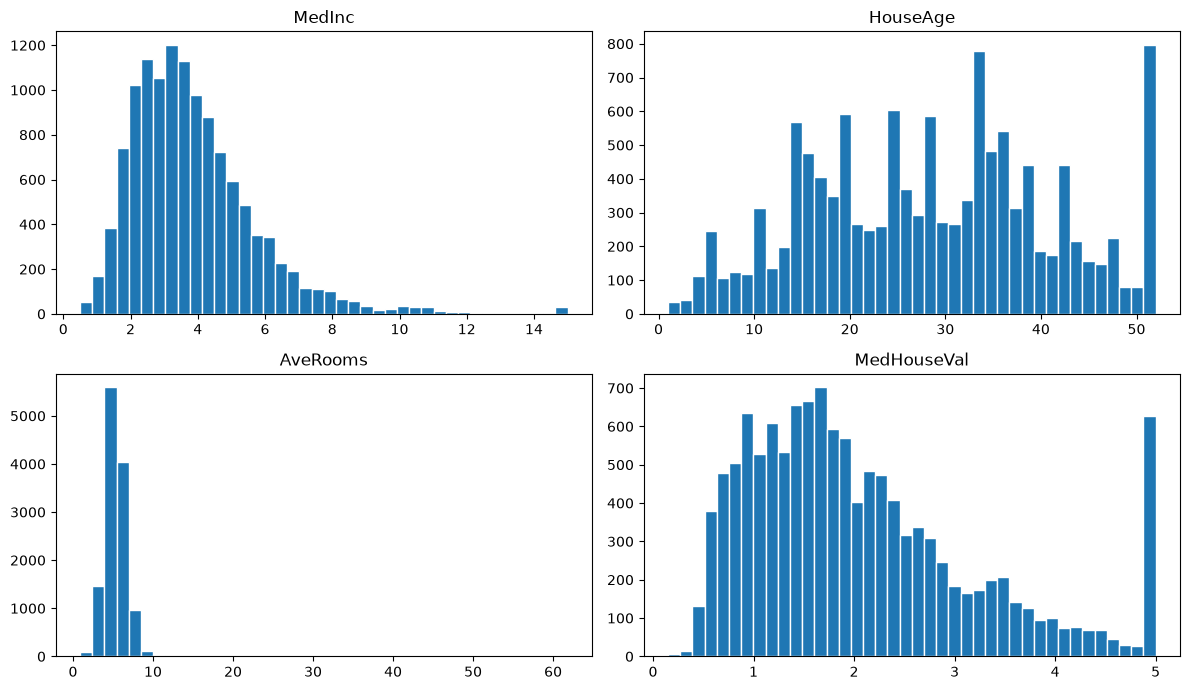

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flatten(), FEATURES + ['MedHouseVal']):
    data = X_train[col] if col in FEATURES else y_train
    ax.hist(data, bins=40, edgecolor='white')
    ax.set_title(col)
plt.tight_layout()
plt.show()

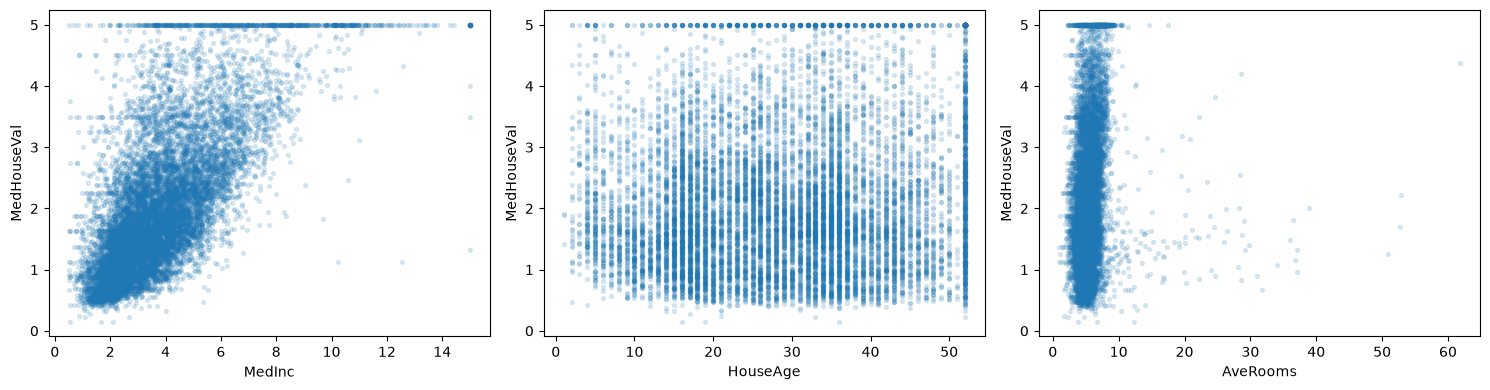

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, FEATURES):
    ax.scatter(X_train[feat], y_train, alpha=0.15, s=8)
    ax.set_xlabel(feat)
    ax.set_ylabel('MedHouseVal')
plt.tight_layout()
plt.show()

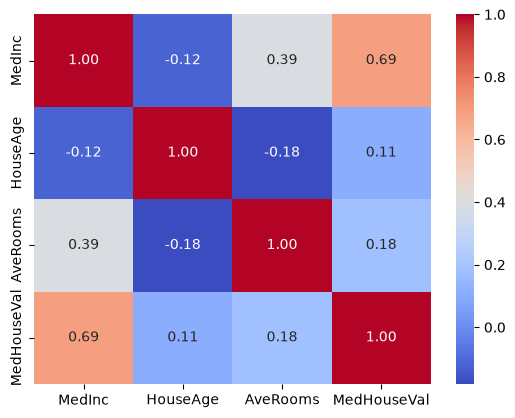

In [26]:
sns.heatmap(X_train.join(y_train).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [27]:
preprocess = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])

X_train_pp = preprocess.fit_transform(X_train)
X_val_pp   = preprocess.transform(X_val)
X_test_pp  = preprocess.transform(X_test)

print('scaled mean ~0:', X_train_pp.mean(axis=0).round(4))
print('scaled std  ~1:', X_train_pp.std(axis=0).round(4))

scaled mean ~0: [0. 0. 0.]
scaled std  ~1: [1. 1. 1.]


## Gradient Descent

In [28]:
n, d = X_train_pp.shape
w, b = np.zeros(d), 0.0
lr, epochs = 0.05, 500
y_tr = y_train.to_numpy()
y_vl = y_val.to_numpy()
train_losses, val_losses = [], []

for epoch in range(epochs):
    y_pred = X_train_pp @ w + b
    error  = y_pred - y_tr
    dw     = (2/n) * (X_train_pp.T @ error)
    db     = (2/n) * np.sum(error)
    w     -= lr * dw
    b     -= lr * db
    train_losses.append(np.mean(error**2))
    val_losses.append(np.mean((X_val_pp @ w + b - y_vl)**2))
    if epoch % 100 == 0:
        print(f'Epoch {epoch}: train={train_losses[-1]:.4f}  val={val_losses[-1]:.4f}')

for feat, wi in zip(FEATURES, w):
    print(f'{feat}: {wi:.4f}')
print(f'bias: {b:.4f}')

Epoch 0: train=5.6015  val=4.7480
Epoch 100: train=0.6404  val=0.6735
Epoch 200: train=0.6404  val=0.6738
Epoch 300: train=0.6404  val=0.6738
Epoch 400: train=0.6404  val=0.6738
MedInc: 0.8548
HouseAge: 0.2076
AveRooms: -0.0932
bias: 2.0681


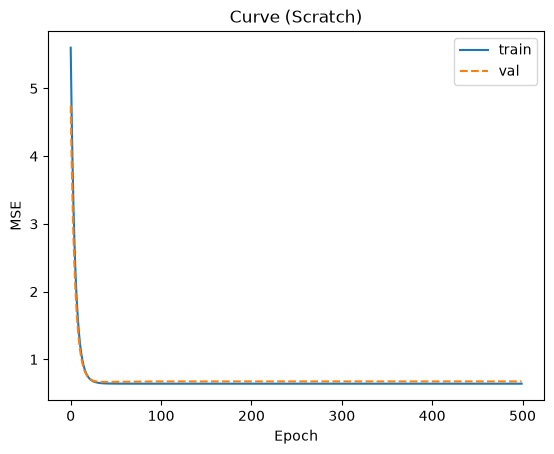

MAE=0.6064  R²=0.5093


In [29]:
plt.plot(train_losses, label='train')
plt.plot(val_losses,   label='val', linestyle='--')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()
plt.title('Curve (Scratch)')
plt.show()

y_pred_s = X_val_pp @ w + b
print(f'MAE={mean_absolute_error(y_val, y_pred_s):.4f}  R²={r2_score(y_val, y_pred_s):.4f}')

## Linear Regression

In [30]:
lr_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
    ('model',  LinearRegression()),
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_val)

print(f'MAE={mean_absolute_error(y_val, y_pred_lr):.4f}  RMSE={np.sqrt(mean_squared_error(y_val, y_pred_lr)):.4f}  R²={r2_score(y_val, y_pred_lr):.4f}')
print(dict(zip(FEATURES, lr_pipe.named_steps['model'].coef_.round(4))))

MAE=0.6064  RMSE=0.8209  R²=0.5093
{'MedInc': np.float64(0.8548), 'HouseAge': np.float64(0.2076), 'AveRooms': np.float64(-0.0932)}


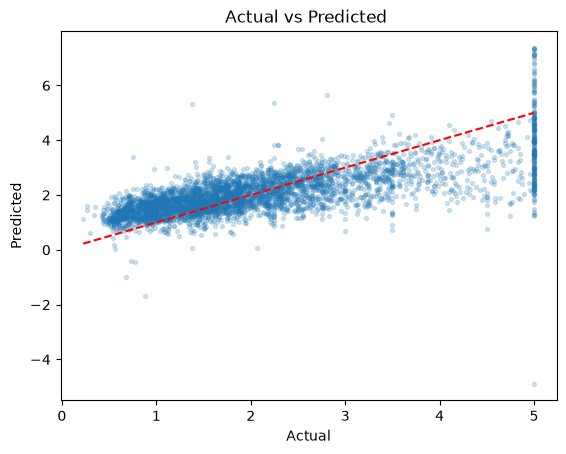

In [31]:
plt.scatter(y_val, y_pred_lr, alpha=0.2, s=8)
lims = [y_val.min(), y_val.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title('Actual vs Predicted ')
plt.show()

In [32]:
models = {
    'LinearReg':    LinearRegression(),
    'Ridge(0.1)':   Ridge(alpha=0.1),
    'Ridge(1.0)':   Ridge(alpha=1.0),
    'Ridge(10)':    Ridge(alpha=10.0),
    'Lasso(0.01)':  Lasso(alpha=0.01, max_iter=5000),
    'Lasso(0.1)':   Lasso(alpha=0.1,  max_iter=5000),
}

rows = {}
for name, est in models.items():
    pipe = Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler()), ('m', est)])
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_val)
    rows[name] = {'MAE': mean_absolute_error(y_val, yp), 'RMSE': np.sqrt(mean_squared_error(y_val, yp)), 'R2': r2_score(y_val, yp)}

pd.DataFrame(rows).T.round(4)

,MAE,RMSE,R2
LinearReg,0.6064,0.8209,0.5093
Ridge(0.1),0.6064,0.8209,0.5093
Ridge(1.0),0.6064,0.8208,0.5093
Ridge(10),0.6065,0.8208,0.5094
Lasso(0.01),0.6075,0.8182,0.5124
Lasso(0.1),0.6269,0.8276,0.5012


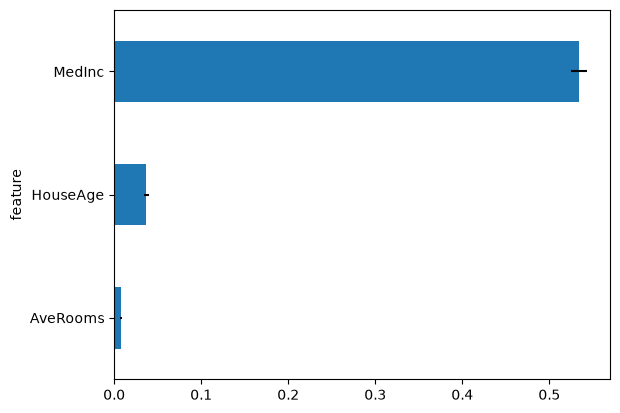

    feature  importance       std
2  AveRooms    0.008070  0.000882
1  HouseAge    0.036649  0.002923
0    MedInc    0.533736  0.009023


In [33]:
imp = permutation_importance(lr_pipe, X_val, y_val, scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEED)
imp_df = pd.DataFrame({'feature': FEATURES, 'importance': imp.importances_mean, 'std': imp.importances_std}).sort_values('importance')

imp_df.plot.barh(x='feature', y='importance', xerr='std', legend=False)
plt.show()
print(imp_df)

## Final Test

In [34]:
y_pred_test = lr_pipe.predict(X_test)
print(f'MAE  = {mean_absolute_error(y_test, y_pred_test):.4f}')
print(f'RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}')
print(f'R²   = {r2_score(y_test, y_pred_test):.4f}')

MAE  = 0.6030
RMSE = 0.8135
R²   = 0.4949


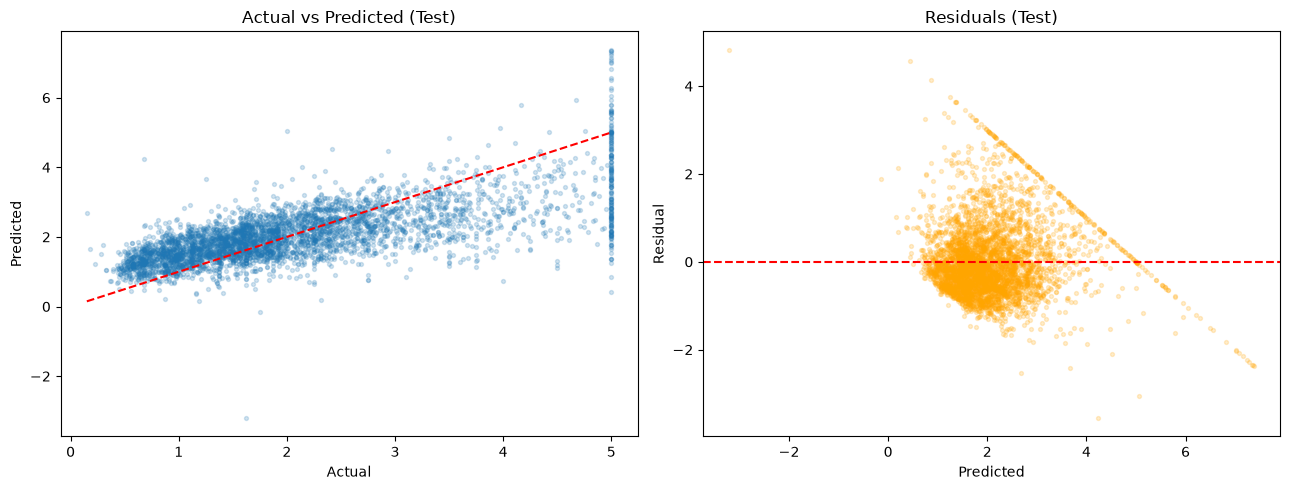

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(y_test, y_pred_test, alpha=0.2, s=8)
lims = [y_test.min(), y_test.max()]
ax1.plot(lims, lims, 'r--')
ax1.set_xlabel('Actual'); ax1.set_ylabel('Predicted'); ax1.set_title('Actual vs Predicted (Test)')

residuals = y_test.to_numpy() - y_pred_test
ax2.scatter(y_pred_test, residuals, alpha=0.2, s=8, color='orange')
ax2.axhline(0, color='red', linestyle='--')
ax2.set_xlabel('Predicted'); ax2.set_ylabel('Residual'); ax2.set_title('Residuals (Test)')

plt.tight_layout()
plt.show()